# U4 · Análisis no supervisado — Perfiles de actividad volcánica
**Equipo 6 · Grupo 9IDGSB · Universidad Tecnológica de Coahuila**

**Objetivo:** agrupar volcanes del Holoceno según su *comportamiento eruptivo* (frecuencia, magnitud, explosividad, recencia) sin usar etiquetas, y reducir la dimensionalidad con PCA para interpretar los grupos.

**Flujo:** datos limpios (U2) → agregación por volcán → transformación y escalado → PCA → K-Means base → optimización (k, DBSCAN, jerárquico) → métricas internas → perfilado e interpretación.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_samples, adjusted_rand_score)
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
OUT_FIG, OUT_RES = "figuras_u4", "resultados_u4"
os.makedirs(OUT_FIG, exist_ok=True); os.makedirs(OUT_RES, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
PAL = sns.color_palette("Set2", 10)
def savefig(name):
    plt.tight_layout(); plt.savefig(f"{OUT_FIG}/{name}.png", dpi=170, bbox_inches="tight"); plt.show()

## 1. Datos y construcción de la unidad de análisis (volcán)
El dataset limpio de la U2 tiene una fila por erupción (9,918). Para describir el *comportamiento* de cada volcán se agrega a una fila por volcán. Solo se conservan volcanes con **al menos una erupción con VEI conocido**, porque la magnitud es parte esencial del perfil.

In [2]:
er = pd.read_csv("erupciones_plano.csv", encoding="utf-8-sig")
ANIO_REF = 2026
er["explosiva"] = (er["vei"] >= 3).astype(float).where(er["vei"].notna())
er["reciente500"] = (er["anio_inicio"] >= ANIO_REF - 500).astype(int)

g = er.groupby("volcano_number")
vol = pd.DataFrame({
    "nombre": g["nombre"].first(), "pais": g["pais"].first(),
    "tipo_volcan": g["tipo_volcan"].first(),
    "latitud": g["latitud"].first(), "longitud": g["longitud"].first(),
    "elevacion_m": g["elevacion_m"].first(),
    "n_erupciones": g.size(),
    "n_con_vei": g["vei"].count(),
    "vei_medio": g["vei"].mean(), "vei_max": g["vei"].max(),
    "pct_explosivas": g["explosiva"].mean(),
    "anio_ultima": g["anio_inicio"].max(),
    "n_ultimos_500": g["reciente500"].sum(),
}).reset_index()
vol["tipo_volcan"] = vol["tipo_volcan"].str.replace(r"\(es\)|\(s\)", "", regex=True).str.strip()
print("Volcanes totales:", len(vol))
vol = vol[vol["n_con_vei"] >= 1].dropna(subset=["latitud", "elevacion_m"]).reset_index(drop=True)
print("Volcanes analizados (≥1 VEI conocido, coordenadas y elevación):", len(vol))

# Variables derivadas / transformadas
vol["abs_latitud"] = vol["latitud"].abs()
vol["log_n_erupciones"] = np.log1p(vol["n_erupciones"])
vol["log_n_ultimos_500"] = np.log1p(vol["n_ultimos_500"])
vol["log_anios_desde_ultima"] = np.log1p(ANIO_REF - vol["anio_ultima"])
FEATS = ["log_n_erupciones", "vei_medio", "vei_max", "pct_explosivas",
         "log_anios_desde_ultima", "log_n_ultimos_500", "elevacion_m", "abs_latitud"]
vol.to_csv(f"{OUT_RES}/dataset_transformado_volcanes.csv", index=False)
vol[["nombre","pais","tipo_volcan"] + FEATS].describe().T.round(2)

Volcanes totales: 854
Volcanes analizados (≥1 VEI conocido, coordenadas y elevación): 682


,count,mean,std,min,25%,50%,75%,max
log_n_erupciones,682.0,2.04,1.09,0.69,1.10,1.79,2.83,5.29
vei_medio,682.0,2.15,1.30,0.00,1.50,2.00,2.90,7.00
vei_max,682.0,3.00,1.66,0.00,2.00,3.00,4.00,7.00
pct_explosivas,682.0,0.34,0.38,0.00,0.00,0.18,0.66,1.00
log_anios_desde_ultima,682.0,4.46,2.16,0.00,2.94,4.32,5.53,9.25
log_n_ultimos_500,682.0,1.51,1.23,0.00,0.69,1.39,2.40,5.25
elevacion_m,682.0,1649.85,1595.32,-4200.00,690.50,1496.00,2491.50,6739.00
abs_latitud,682.0,29.26,20.05,0.02,11.00,29.75,45.39,85.61


### Distribución de las variables y correlaciones
`n_erupciones` y `n_ultimos_500` tienen cola larga → se aplicó `log1p`. Las variables tienen escalas muy distintas (elevación en miles de metros vs. VEI de 0 a 7), por lo que se estandariza antes de cualquier algoritmo basado en distancias.

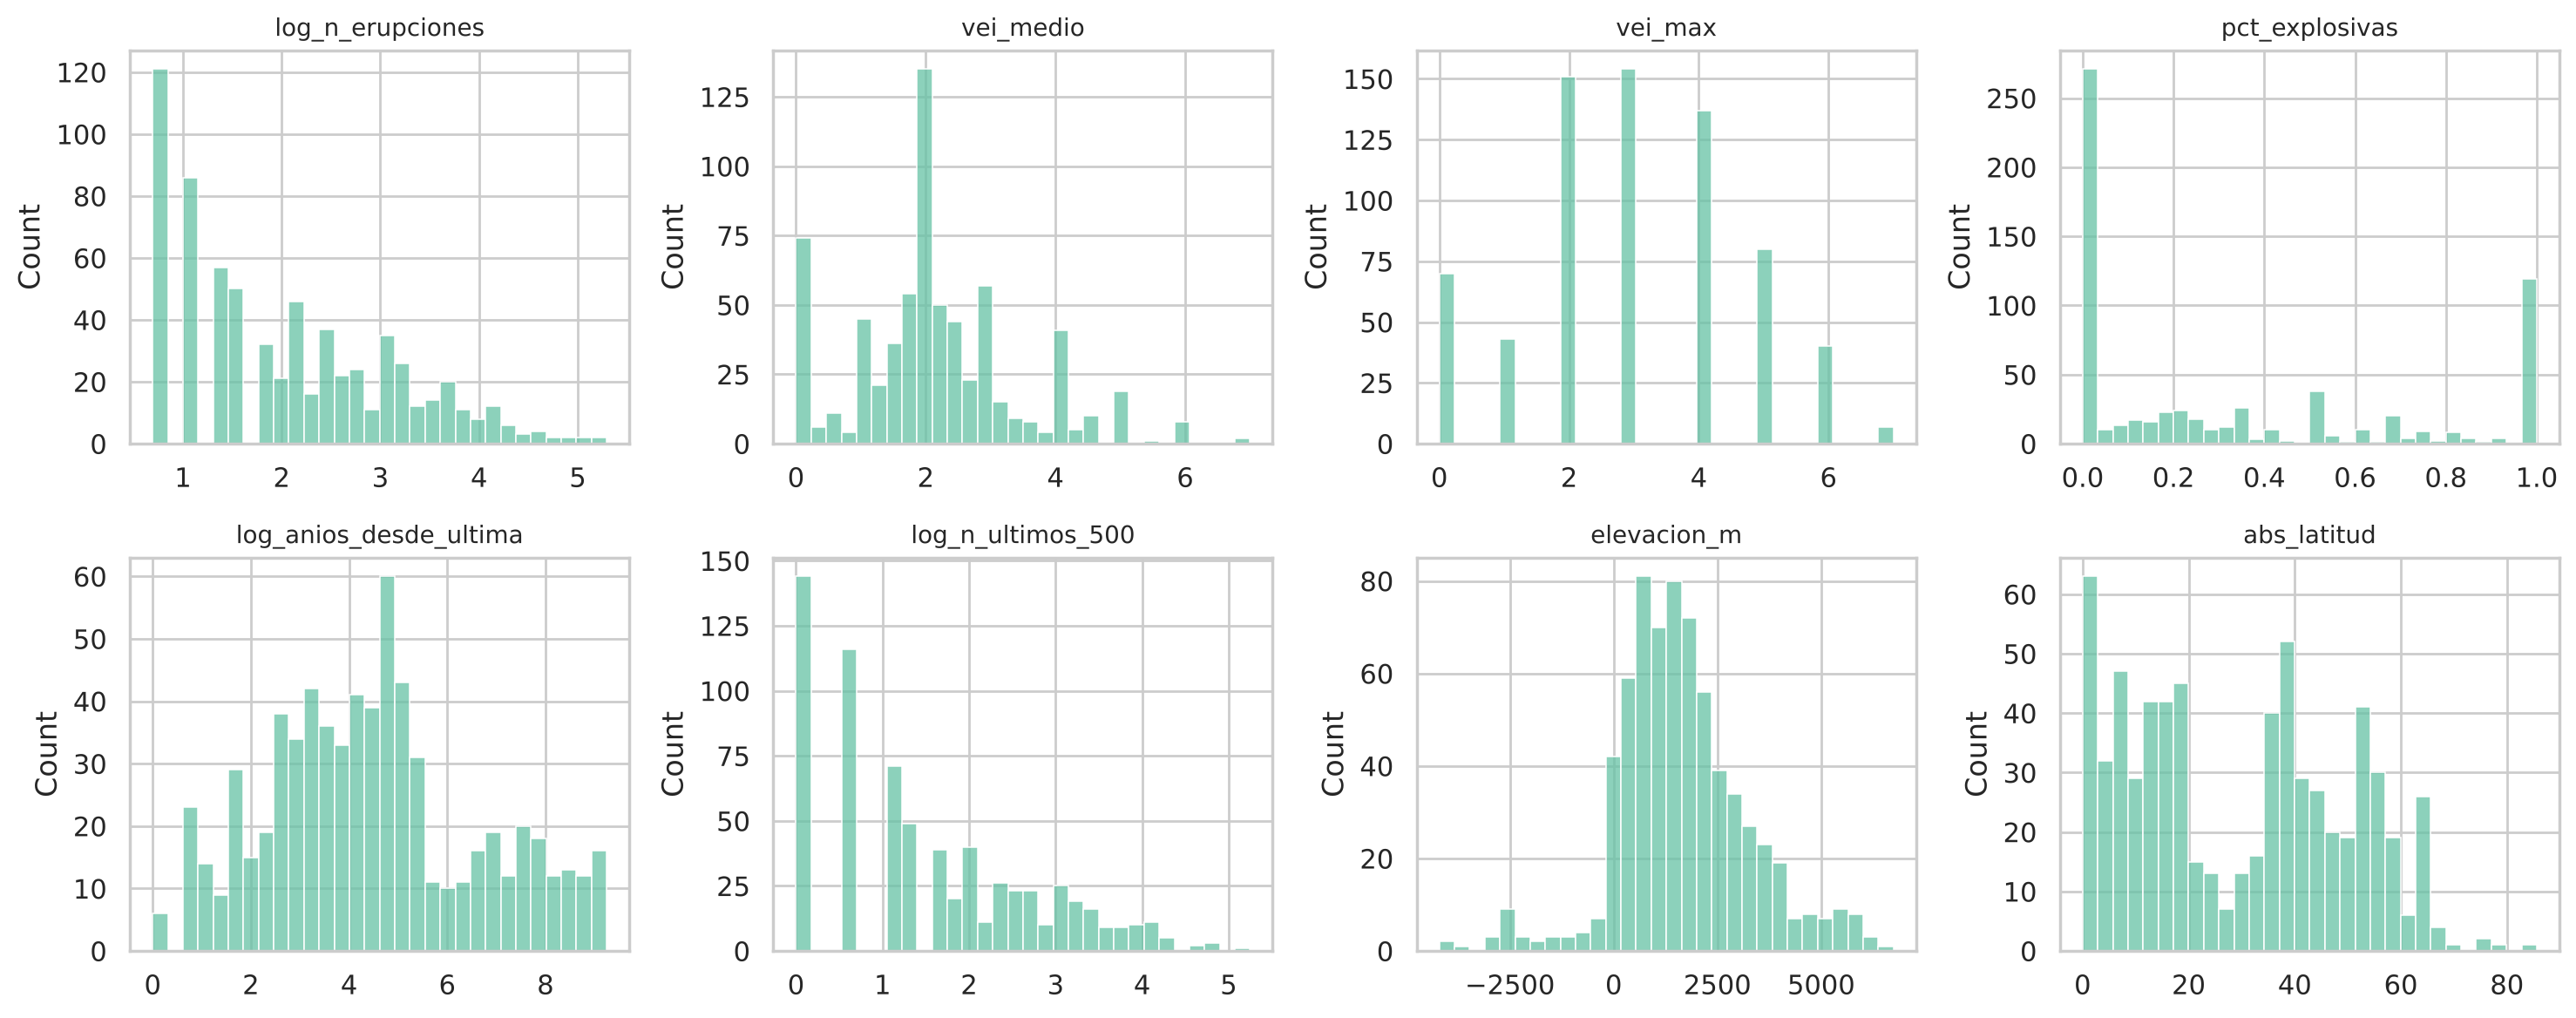

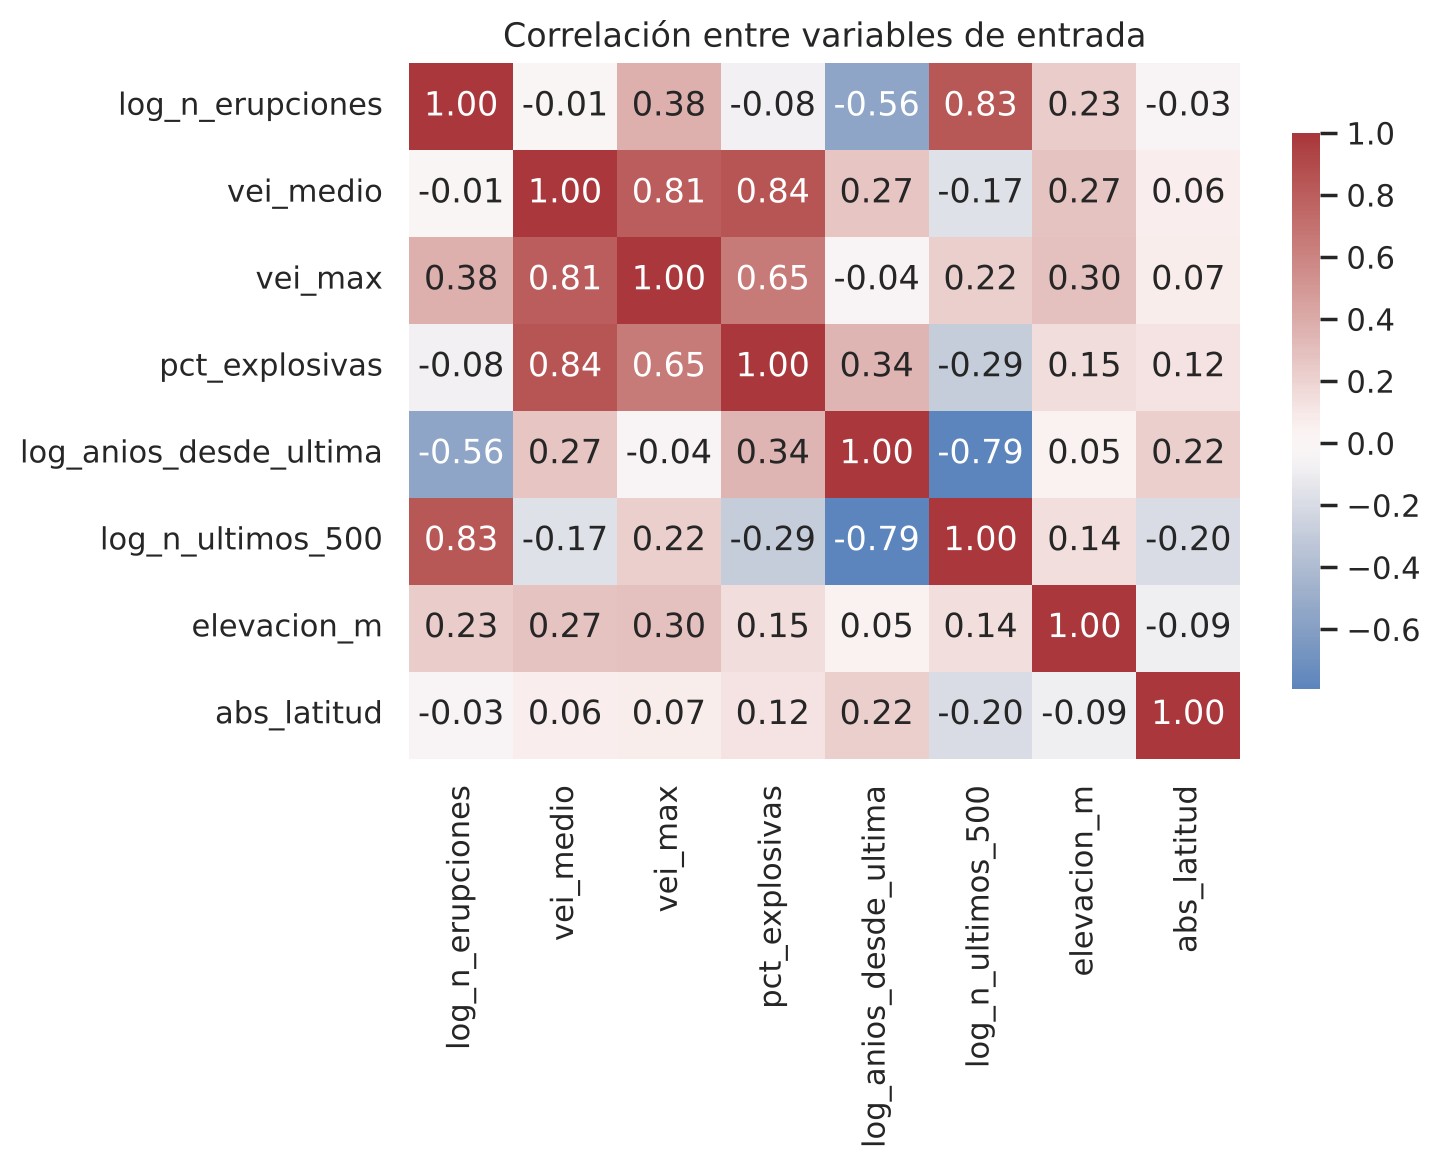

In [3]:
fig, ax = plt.subplots(2, 4, figsize=(15, 6))
for a, f in zip(ax.ravel(), FEATS):
    sns.histplot(vol[f], bins=30, ax=a, color=PAL[0]); a.set_title(f, fontsize=10); a.set_xlabel("")
savefig("01_distribuciones")
plt.figure(figsize=(7.5, 6))
sns.heatmap(vol[FEATS].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, cbar_kws={"shrink": .8})
plt.title("Correlación entre variables de entrada")
savefig("02_correlacion")

In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(vol[FEATS])         # espacio estandarizado (referencia para todas las métricas)
X_raw = vol[FEATS].values                    # sin escalar (solo para el modelo "antes")

## 2. Reducción de dimensionalidad: PCA

Varianza explicada por componente: [0.356 0.321 0.127 0.107 0.042 0.027 0.012 0.009]
Componentes para ≥90% de varianza: 4


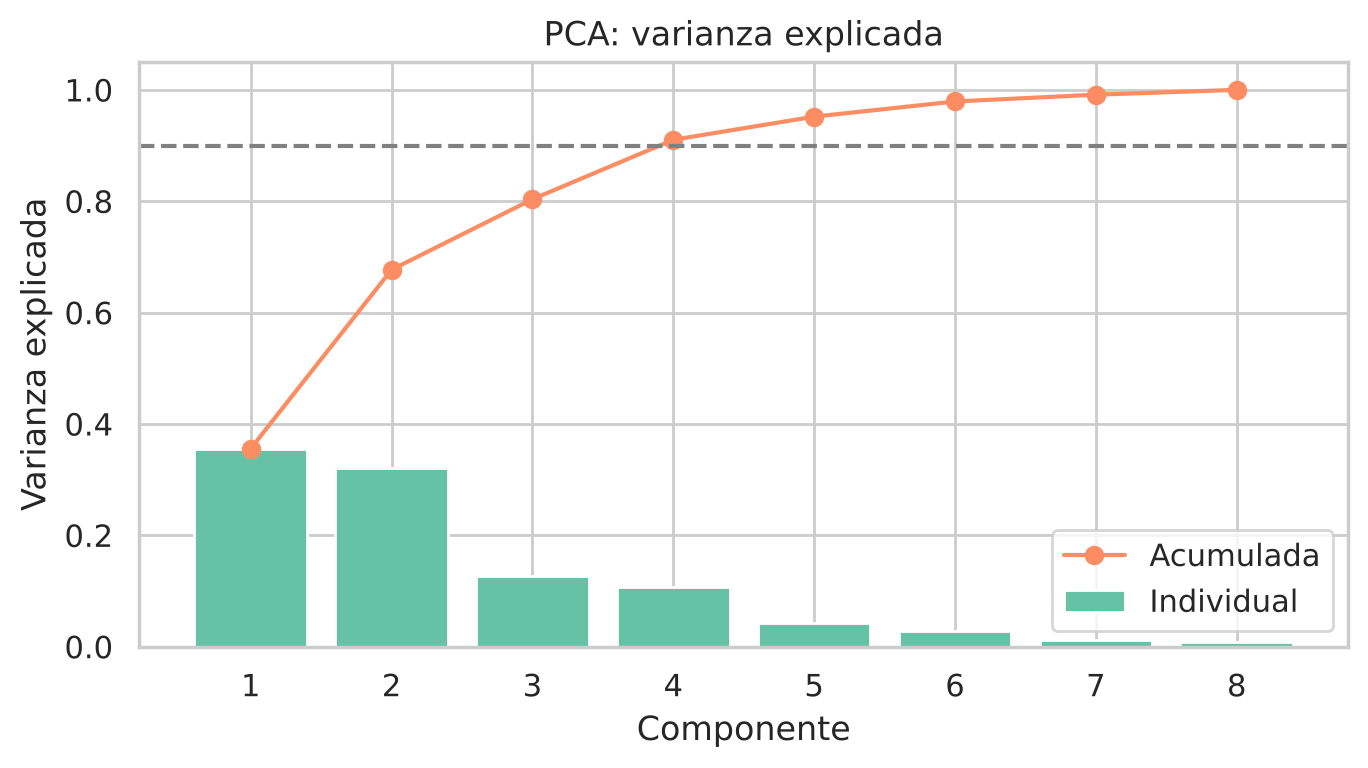

,PC1,PC2,PC3
log_n_erupciones,-0.264,0.486,0.191
vei_medio,0.474,0.324,-0.044
vei_max,0.294,0.496,0.096
pct_explosivas,0.493,0.231,0.024
log_anios_desde_ultima,0.428,-0.300,-0.069
log_n_ultimos_500,-0.399,0.434,0.072
elevacion_m,0.097,0.278,-0.445
abs_latitud,0.154,-0.070,0.862


In [5]:
pca_full = PCA(random_state=SEED).fit(X)
ev = pca_full.explained_variance_ratio_
cum = ev.cumsum()
n90 = int(np.argmax(cum >= 0.90) + 1)
print("Varianza explicada por componente:", np.round(ev, 3))
print(f"Componentes para ≥90% de varianza: {n90}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(ev)+1), ev, color=PAL[0], label="Individual")
ax.plot(range(1, len(ev)+1), cum, "o-", color=PAL[1], label="Acumulada")
ax.axhline(0.9, ls="--", color="gray"); ax.set_xlabel("Componente"); ax.set_ylabel("Varianza explicada")
ax.set_title("PCA: varianza explicada"); ax.legend()
savefig("03_pca_varianza")
pca = PCA(n_components=n90, random_state=SEED).fit(X)
Z = pca.transform(X)
load = pd.DataFrame(pca.components_[:3].T, index=FEATS, columns=["PC1", "PC2", "PC3"]).round(3)
load.to_csv(f"{OUT_RES}/pca_cargas.csv"); pd.DataFrame({"componente":[f"PC{i+1}" for i in range(len(ev))],"varianza":ev.round(4),"acumulada":cum.round(4)}).to_csv(f"{OUT_RES}/pca_varianza.csv", index=False)
load

## 3. Modelo inicial (ANTES de optimizar)
K-Means con **k = 3 elegido arbitrariamente** y aplicado a los datos **sin escalar** (lo que haría una primera implementación ingenua). Las métricas se calculan en el espacio estandarizado para que sean comparables con el modelo final.

In [6]:
def metricas(Xe, lab):
    m = lab != -1
    if len(set(lab[m])) < 2: return dict(silhouette=np.nan, calinski_harabasz=np.nan, davies_bouldin=np.nan)
    return dict(silhouette=silhouette_score(Xe[m], lab[m]),
                calinski_harabasz=calinski_harabasz_score(Xe[m], lab[m]),
                davies_bouldin=davies_bouldin_score(Xe[m], lab[m]))
km0 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_raw)
base = {"modelo": "K-Means k=3, sin escalar (base)", "k": 3, **metricas(X, km0.labels_)}
print(pd.Series(km0.labels_).value_counts().sort_index().to_dict(), base)

{0: 332, 1: 125, 2: 225} {'modelo': 'K-Means k=3, sin escalar (base)', 'k': 3, 'silhouette': 0.05156460146544151, 'calinski_harabasz': 46.76435785280484, 'davies_bouldin': 3.5020367319674377}


## 4. Optimización
### 4.1 Selección de k para K-Means (datos estandarizados)
Se prueban k = 2…10 con tres métricas internas: **Silhouette** (↑), **Calinski-Harabasz** (↑) y **Davies-Bouldin** (↓), más el método del codo (inercia).

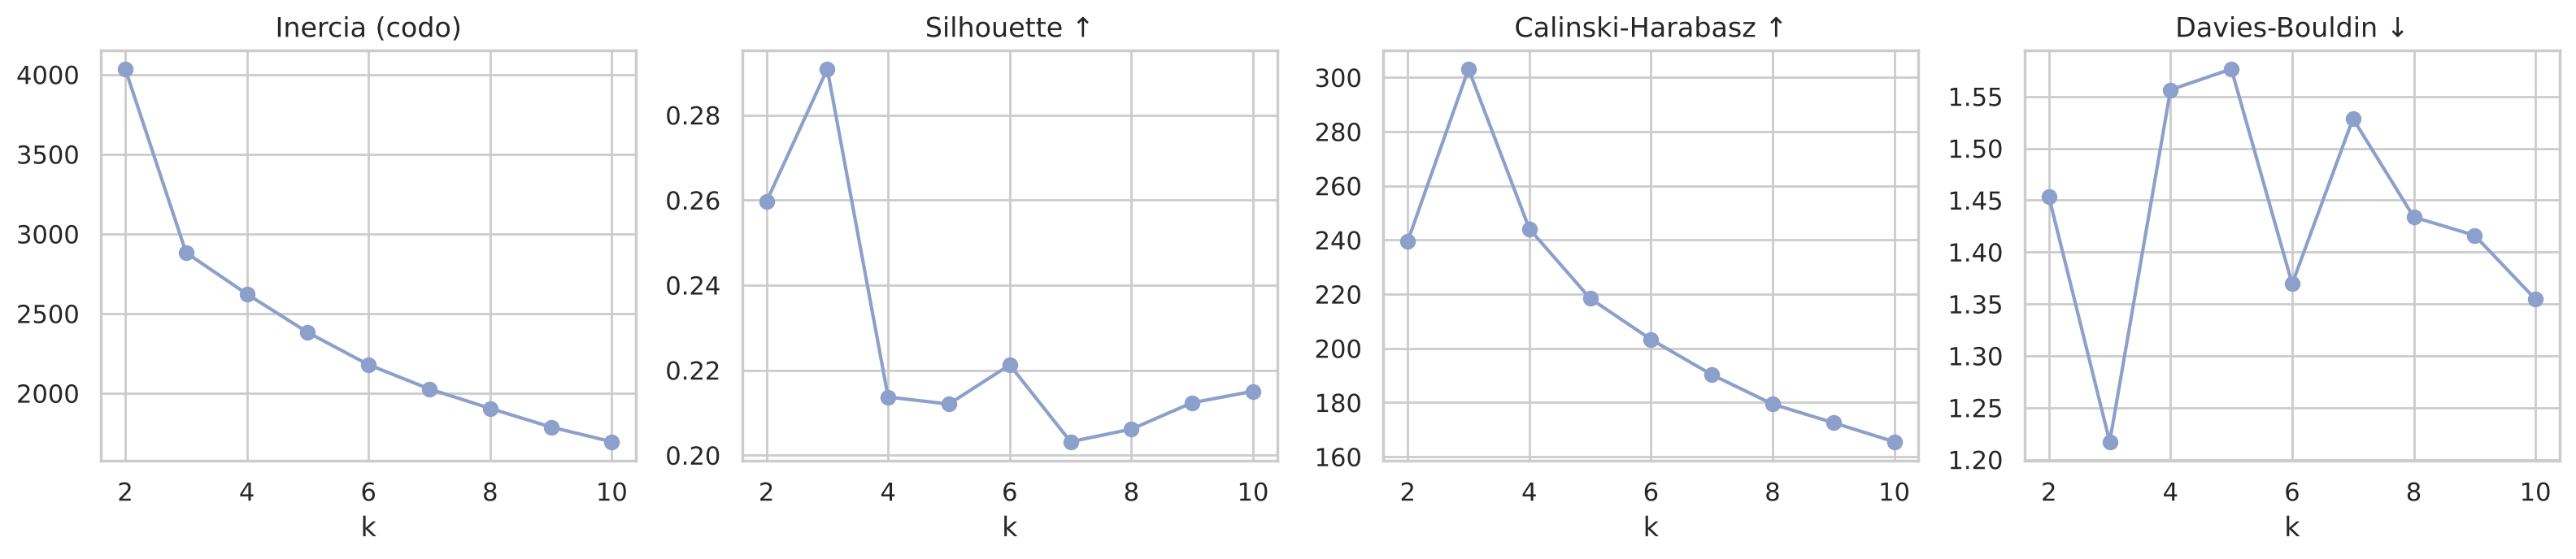

,k,inercia,silhouette,calinski_harabasz,davies_bouldin
0,2,4034.819,0.260,239.516,1.453
1,3,2882.499,0.291,303.106,1.217
2,4,2622.763,0.214,244.136,1.556
3,5,2381.876,0.212,218.439,1.576
4,6,2179.154,0.221,203.303,1.369
5,7,2027.093,0.203,190.298,1.529
6,8,1905.318,0.206,179.435,1.434
7,9,1788.148,0.212,172.557,1.416
8,10,1695.972,0.215,165.539,1.355


In [7]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    rows.append(dict(k=k, inercia=km.inertia_, **metricas(X, km.labels_)))
kdf = pd.DataFrame(rows)
kdf.to_csv(f"{OUT_RES}/kmeans_barrido_k.csv", index=False)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, (c, t) in zip(ax, [("inercia","Inercia (codo)"),("silhouette","Silhouette ↑"),("calinski_harabasz","Calinski-Harabasz ↑"),("davies_bouldin","Davies-Bouldin ↓")]):
    a.plot(kdf.k, kdf[c], "o-", color=PAL[2]); a.set_title(t); a.set_xlabel("k")
savefig("04_barrido_k")
kdf.round(3)

### 4.2 Comparación de algoritmos y configuraciones
- **K-Means** sobre datos estandarizados y sobre los componentes PCA.
- **Clustering jerárquico (Ward)**.
- **DBSCAN** con búsqueda en malla de `eps` y `min_samples` (las métricas se calculan solo sobre puntos no ruido; se reporta el % de ruido).

In [8]:
def rank_k(df):
    r = (df.silhouette.rank(ascending=False) + df.calinski_harabasz.rank(ascending=False) + df.davies_bouldin.rank(ascending=True))
    return int(df.loc[r.idxmin(), "k"])
k_best_std = rank_k(kdf)
rows_pca = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    rows_pca.append(dict(k=k, **metricas(Z, km.labels_)))
kdf_pca = pd.DataFrame(rows_pca); k_best_pca = rank_k(kdf_pca)
rows_h = []
for k in range(2, 11):
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    rows_h.append(dict(k=k, **metricas(X, ag.labels_)))
kdf_h = pd.DataFrame(rows_h); k_best_h = rank_k(kdf_h)
rows_d = []
for eps in np.arange(0.6, 2.6, 0.2):
    for ms in [5, 10, 15, 20]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        ncl = len(set(lab)) - (1 if -1 in lab else 0)
        if ncl >= 2:
            rows_d.append(dict(eps=round(eps,1), min_samples=ms, k=ncl, pct_ruido=(lab==-1).mean()*100, **metricas(X, lab)))
ddf = pd.DataFrame(rows_d)
ddf.to_csv(f"{OUT_RES}/dbscan_malla.csv", index=False)
# DBSCAN válido: ruido ≤ 15%
dv = ddf[ddf.pct_ruido <= 15]
best_db = dv.sort_values("silhouette", ascending=False).iloc[0] if len(dv) else ddf.sort_values("silhouette", ascending=False).iloc[0]
print("Mejor k  K-Means std:", k_best_std, "| K-Means PCA:", k_best_pca, "| Ward:", k_best_h)
print("Mejor DBSCAN:\n", best_db.round(3).to_dict())

km_std = KMeans(n_clusters=k_best_std, n_init=20, random_state=SEED).fit(X)
km_pca = KMeans(n_clusters=k_best_pca, n_init=20, random_state=SEED).fit(Z)
ag_best = AgglomerativeClustering(n_clusters=k_best_h, linkage="ward").fit(X)
db_best = DBSCAN(eps=best_db.eps, min_samples=int(best_db.min_samples)).fit(X)
comp = pd.DataFrame([
    base,
    {"modelo": f"K-Means estandarizado (k={k_best_std})", "k": k_best_std, **metricas(X, km_std.labels_)},
    {"modelo": f"K-Means sobre PCA (k={k_best_pca}, {n90} comp.)", "k": k_best_pca, **metricas(X, km_pca.labels_)},
    {"modelo": f"Jerárquico Ward (k={k_best_h})", "k": k_best_h, **metricas(X, ag_best.labels_)},
    {"modelo": f"DBSCAN (eps={best_db.eps}, ms={int(best_db.min_samples)})", "k": int(best_db.k), **metricas(X, db_best.labels_)},
])
comp["pct_ruido"] = [0, 0, 0, 0, (db_best.labels_ == -1).mean() * 100]
comp.round(3).to_csv(f"{OUT_RES}/comparacion_modelos.csv", index=False)
comp.round(3)

Mejor k  K-Means std: 3 | K-Means PCA: 3 | Ward: 3
Mejor DBSCAN:
 {'eps': 1.0, 'min_samples': 20.0, 'k': 2.0, 'pct_ruido': 91.349, 'silhouette': 0.609, 'calinski_harabasz': 148.668, 'davies_bouldin': 0.554}


,modelo,k,silhouette,calinski_harabasz,davies_bouldin,pct_ruido
0,"K-Means k=3, sin escalar (base)",3,0.052,46.764,3.502,0.000
1,K-Means estandarizado (k=3),3,0.291,303.106,1.217,0.000
2,"K-Means sobre PCA (k=3, 4 comp.)",3,0.291,303.106,1.217,0.000
3,Jerárquico Ward (k=3),3,0.253,254.918,1.328,0.000
4,"DBSCAN (eps=1.0, ms=20)",2,0.609,148.668,0.554,91.349


### 4.3 Selección del modelo final
Se elige por **suma de rangos** de las tres métricas entre los modelos sin ruido (K-Means std, K-Means PCA, Ward) y se verifica interpretabilidad (grupos no triviales, tamaños razonables).

In [9]:
cand = comp.iloc[1:4].copy()
cand["rango"] = (cand.silhouette.rank(ascending=False) + cand.calinski_harabasz.rank(ascending=False) + cand.davies_bouldin.rank())
print(cand[["modelo","silhouette","calinski_harabasz","davies_bouldin","rango"]].round(3))
final_name = cand.sort_values("rango").iloc[0]["modelo"]
print("Modelo final:", final_name)
if final_name.startswith("K-Means estandarizado"): labels, K = km_std.labels_, k_best_std
elif final_name.startswith("K-Means sobre PCA"):   labels, K = km_pca.labels_, k_best_pca
else:                                              labels, K = ag_best.labels_, k_best_h

# Antes vs después
ant_des = pd.DataFrame([base, {"modelo": f"FINAL: {final_name}", "k": K, **metricas(X, labels)}])
ant_des["mejora_silhouette_%"] = [np.nan, (ant_des.silhouette[1]/ant_des.silhouette[0]-1)*100]
ant_des.round(3).to_csv(f"{OUT_RES}/antes_vs_despues.csv", index=False)
ant_des.round(3)

                             modelo  silhouette  calinski_harabasz  \
1       K-Means estandarizado (k=3)       0.291            303.106   
2  K-Means sobre PCA (k=3, 4 comp.)       0.291            303.106   
3             Jerárquico Ward (k=3)       0.253            254.918   

   davies_bouldin  rango  
1           1.217    4.5  
2           1.217    4.5  
3           1.328    9.0  
Modelo final: K-Means estandarizado (k=3)


,modelo,k,silhouette,calinski_harabasz,davies_bouldin,mejora_silhouette_%
0,"K-Means k=3, sin escalar (base)",3,0.052,46.764,3.502,NaN
1,FINAL: K-Means estandarizado (k=3),3,0.291,303.106,1.217,464.015


### 4.4 Estabilidad del modelo final
Se remuestrea el 80 % de los volcanes 30 veces, se reagrupa con el mismo algoritmo y se compara con la partición completa mediante el **Adjusted Rand Index** (ARI; 1 = idéntico).

In [10]:
rng = np.random.RandomState(SEED); aris = []
for _ in range(30):
    idx = rng.choice(len(X), int(.8*len(X)), replace=False)
    if final_name.startswith("Jer"):
        sub = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X[idx])
    else:
        Xs = Z if "PCA" in final_name else X
        sub = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(Xs[idx])
    aris.append(adjusted_rand_score(labels[idx], sub))
print(f"ARI medio = {np.mean(aris):.3f}  (±{np.std(aris):.3f})")
json.dump({"ari_medio": float(np.mean(aris)), "ari_sd": float(np.std(aris))}, open(f"{OUT_RES}/estabilidad.json","w"))

ARI medio = 0.970  (±0.016)


## 5. Resultados: visualización de los grupos

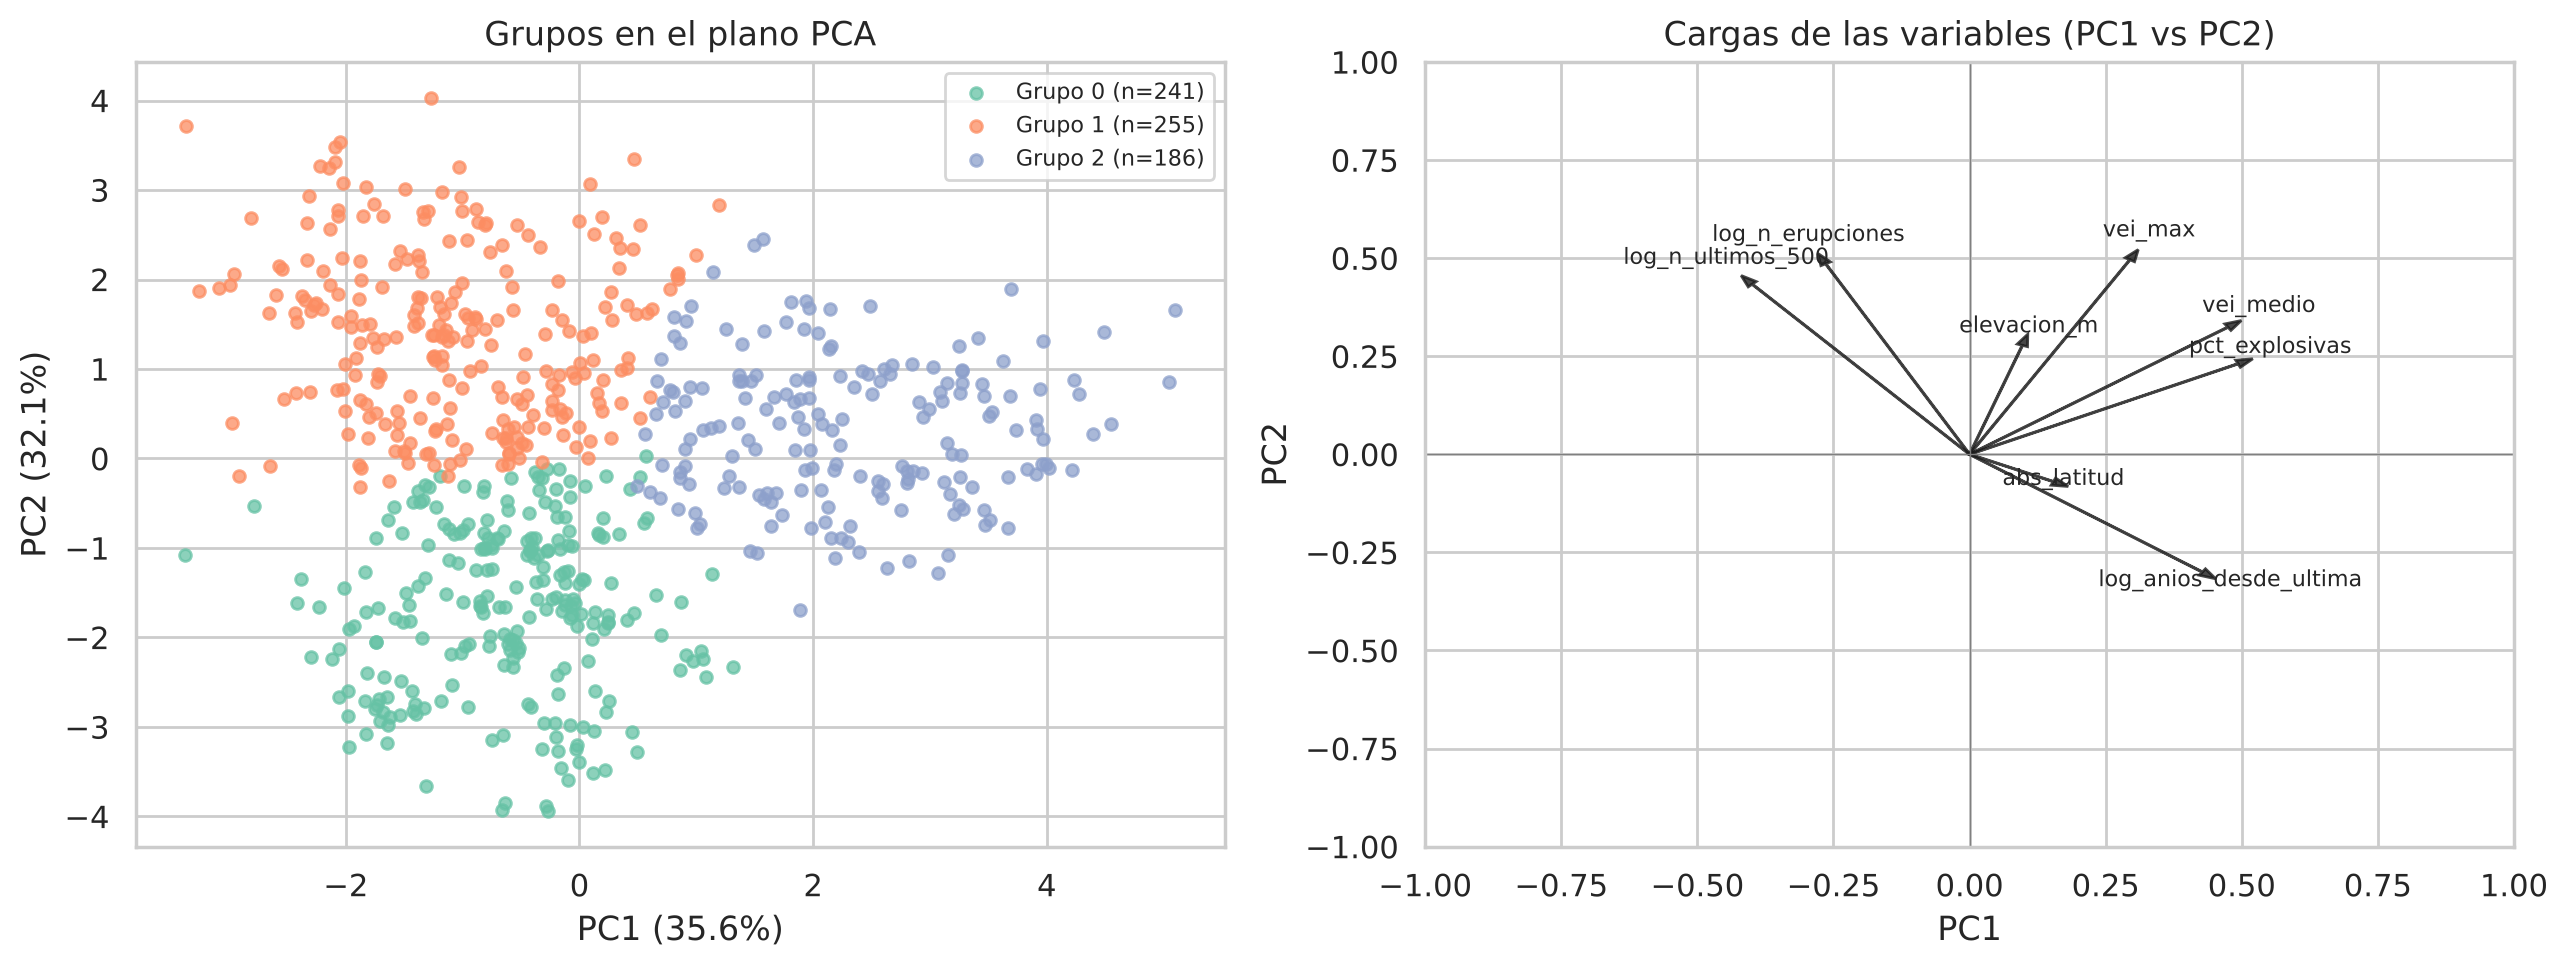

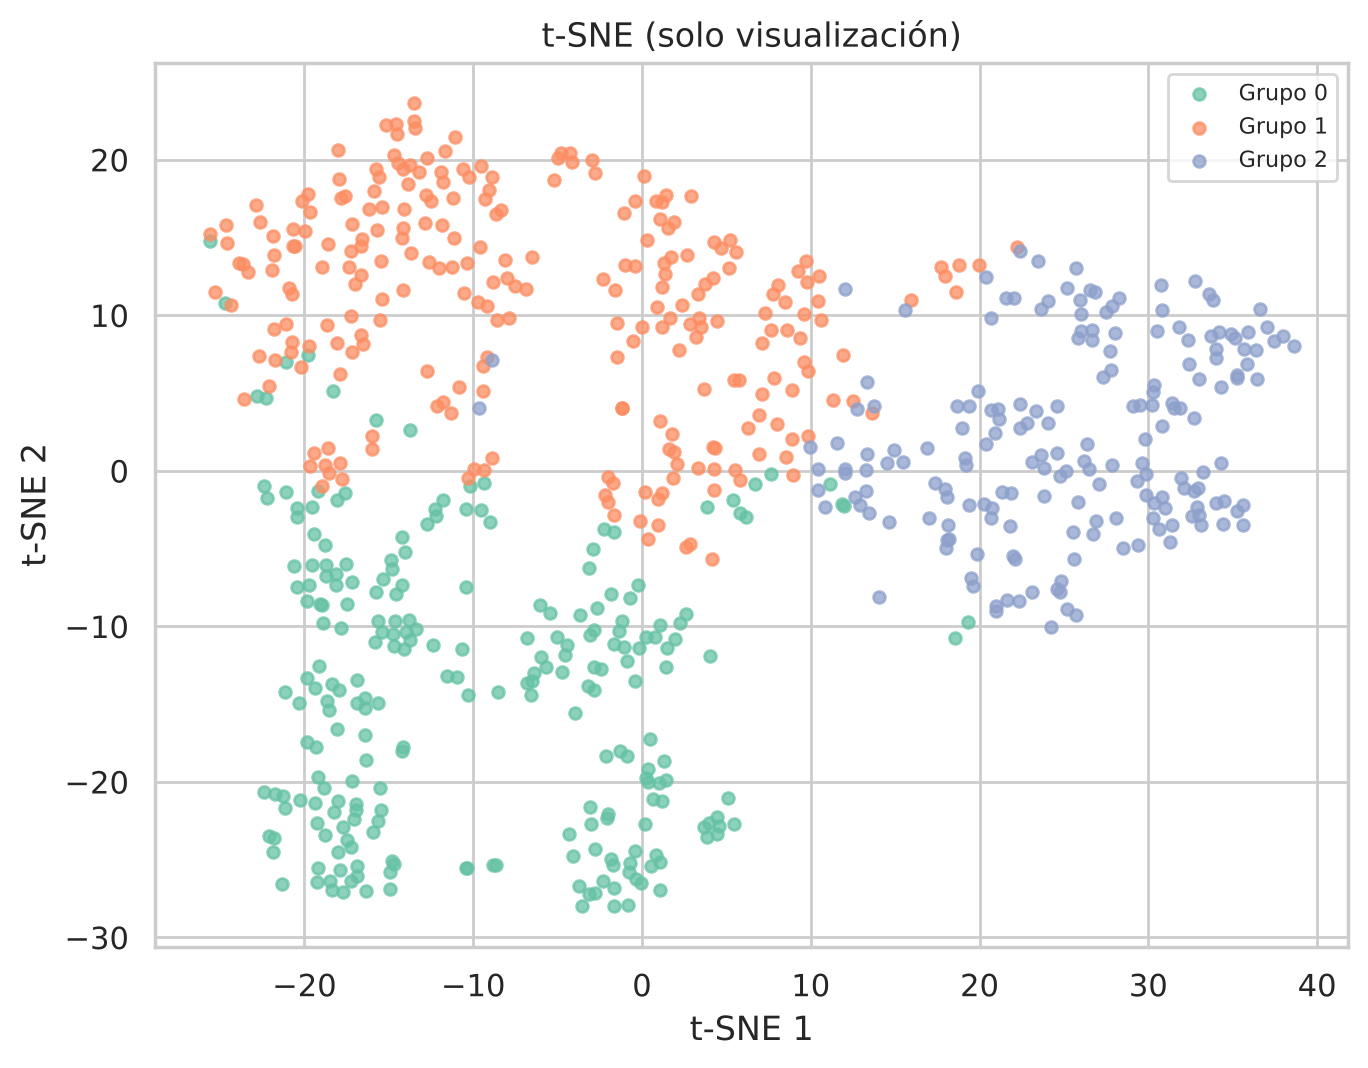

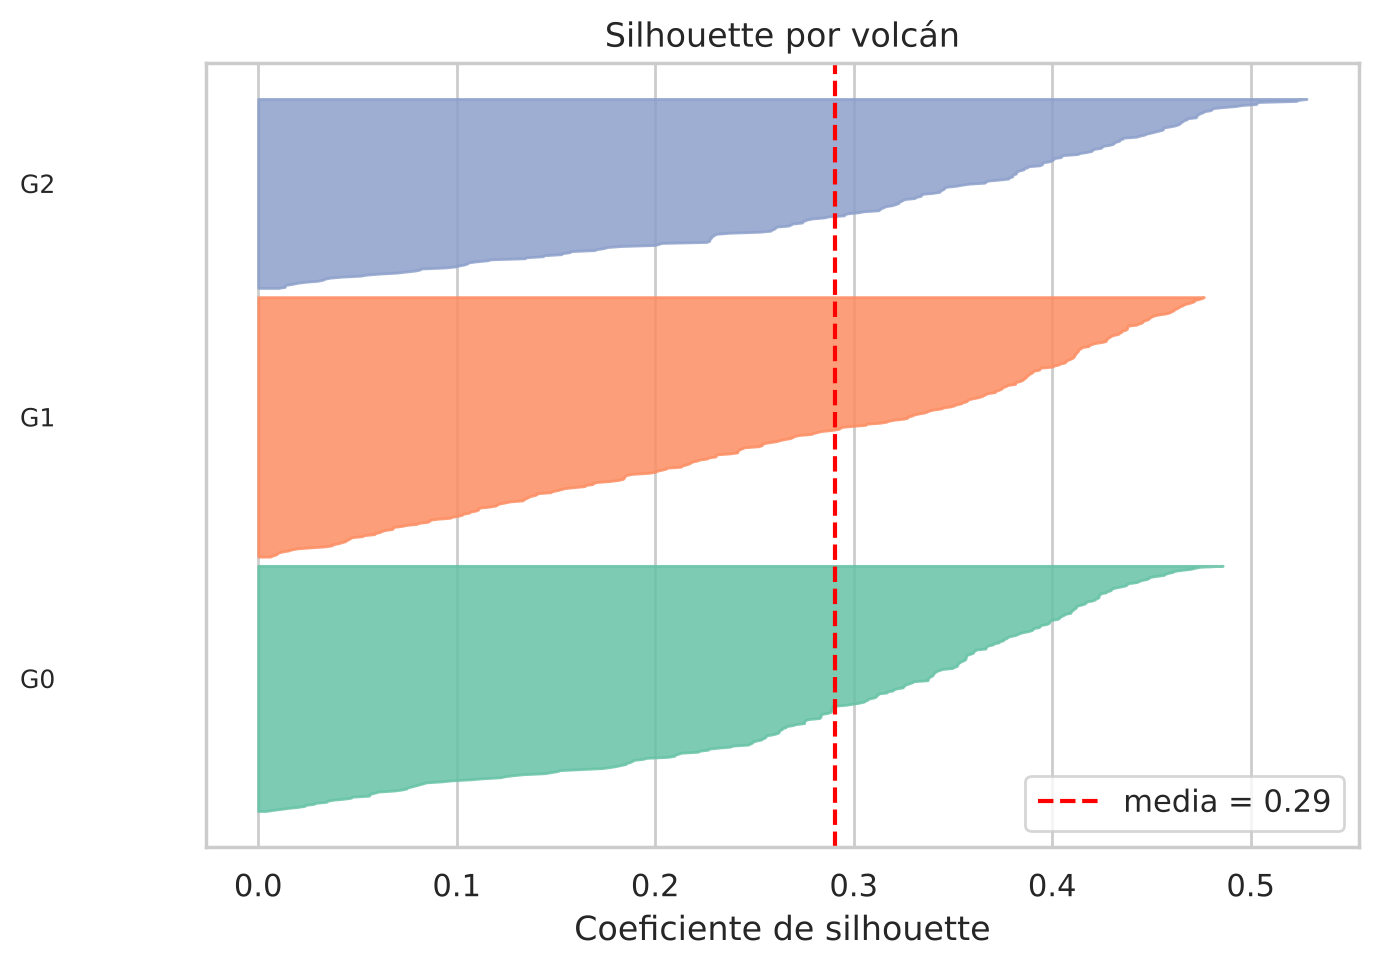

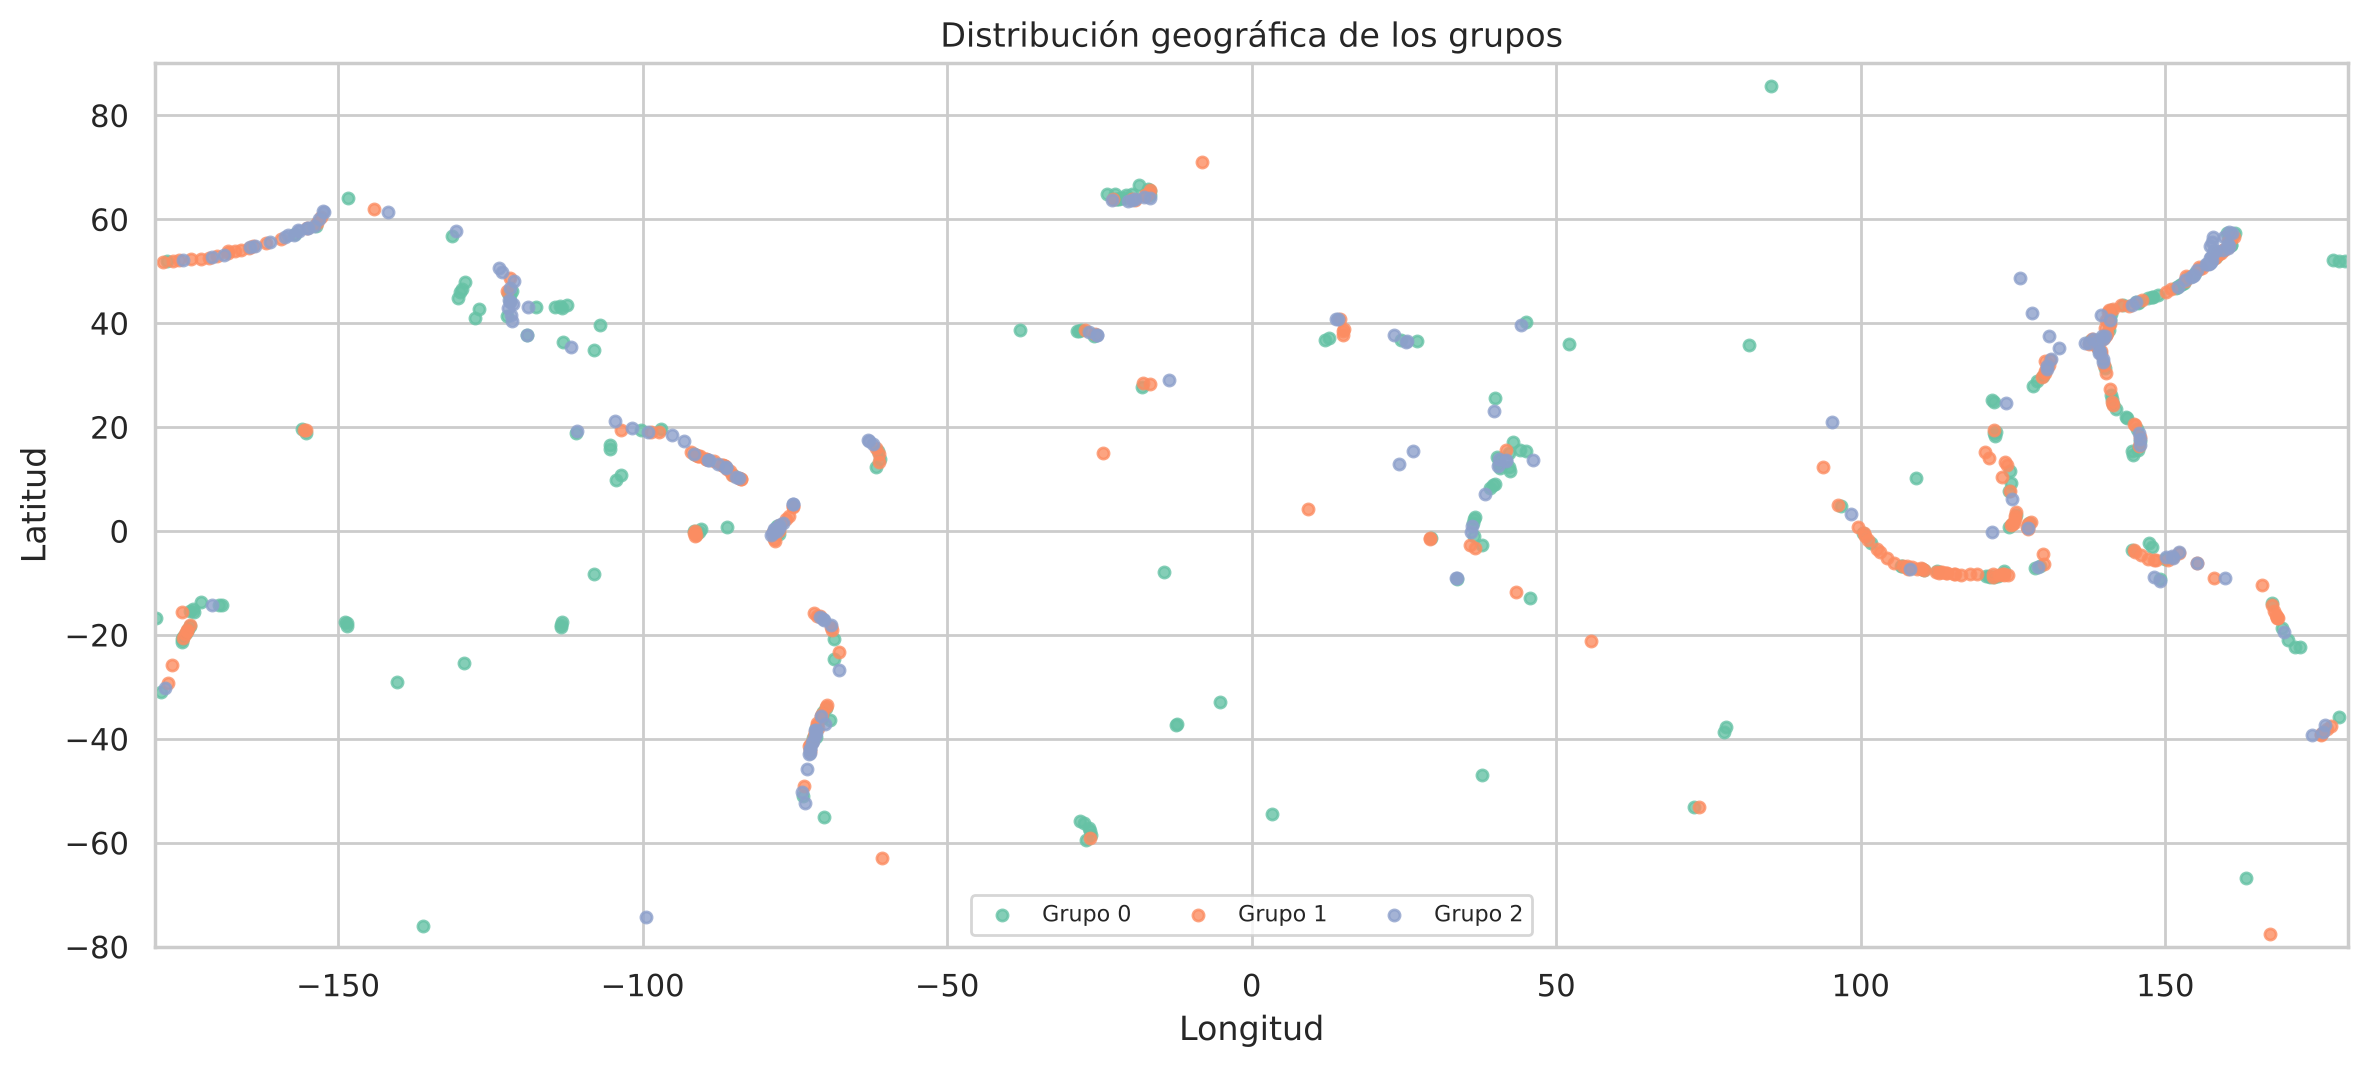

In [11]:
# Reordenar etiquetas por vei_medio ascendente para una lectura consistente
vol["cluster"] = labels
orden = vol.groupby("cluster")["vei_medio"].mean().sort_values().index
remap = {old: new for new, old in enumerate(orden)}
vol["cluster"] = vol["cluster"].map(remap)
lab = vol["cluster"].values
vol.to_csv(f"{OUT_RES}/volcanes_con_cluster.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c in range(K):
    m = lab == c
    ax[0].scatter(Z[m,0], Z[m,1], s=18, alpha=.75, color=PAL[c], label=f"Grupo {c} (n={m.sum()})")
ax[0].set_xlabel(f"PC1 ({ev[0]*100:.1f}%)"); ax[0].set_ylabel(f"PC2 ({ev[1]*100:.1f}%)"); ax[0].set_title("Grupos en el plano PCA"); ax[0].legend(fontsize=8)
# Biplot de cargas
for f, (a, b) in zip(FEATS, pca.components_[:2].T):
    ax[1].arrow(0, 0, a, b, color="k", head_width=.02, alpha=.8); ax[1].text(a*1.12, b*1.12, f, fontsize=8, ha="center")
ax[1].set_xlim(-1, 1); ax[1].set_ylim(-1, 1); ax[1].axhline(0, c="gray", lw=.5); ax[1].axvline(0, c="gray", lw=.5)
ax[1].set_title("Cargas de las variables (PC1 vs PC2)"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
savefig("05_pca_clusters_cargas")

tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(X)
plt.figure(figsize=(7, 5.5))
for c in range(K):
    m = lab == c; plt.scatter(tsne[m,0], tsne[m,1], s=18, alpha=.75, color=PAL[c], label=f"Grupo {c}")
plt.title("t-SNE (solo visualización)"); plt.legend(fontsize=8); plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2")
savefig("06_tsne")

# Silhouette por muestra
sil = silhouette_samples(X, lab); plt.figure(figsize=(7, 5)); y0 = 0
for c in range(K):
    s = np.sort(sil[lab == c]); plt.fill_betweenx(np.arange(y0, y0+len(s)), 0, s, color=PAL[c], alpha=.85); plt.text(-0.12, y0+len(s)/2, f"G{c}", fontsize=9); y0 += len(s)+8
plt.axvline(sil.mean(), color="red", ls="--", label=f"media = {sil.mean():.2f}"); plt.legend(); plt.xlabel("Coeficiente de silhouette"); plt.yticks([]); plt.title("Silhouette por volcán")
savefig("07_silhouette_muestras")

# Mapa
plt.figure(figsize=(12, 5.5))
for c in range(K):
    m = lab == c; plt.scatter(vol.longitud[m], vol.latitud[m], s=16, alpha=.8, color=PAL[c], label=f"Grupo {c}")
plt.xlim(-180, 180); plt.ylim(-80, 90); plt.xlabel("Longitud"); plt.ylabel("Latitud"); plt.legend(ncol=K, fontsize=8, loc="lower center"); plt.title("Distribución geográfica de los grupos")
savefig("08_mapa_clusters")

### Perfil de cada grupo

           n  erupciones_med  vei_medio  vei_max  pct_explosivas  anios_desde_ultima  erup_ult500  elevacion_m  abs_lat
cluster                                                                                                                
0        241             2.0       1.08     1.34            0.02               112.0          1.0       994.11    29.40
1        255            21.0       2.04     3.62            0.25                16.0         15.0      2109.04    25.65
2        186             3.0       3.69     4.29            0.86               436.0          1.0      1869.98    34.01


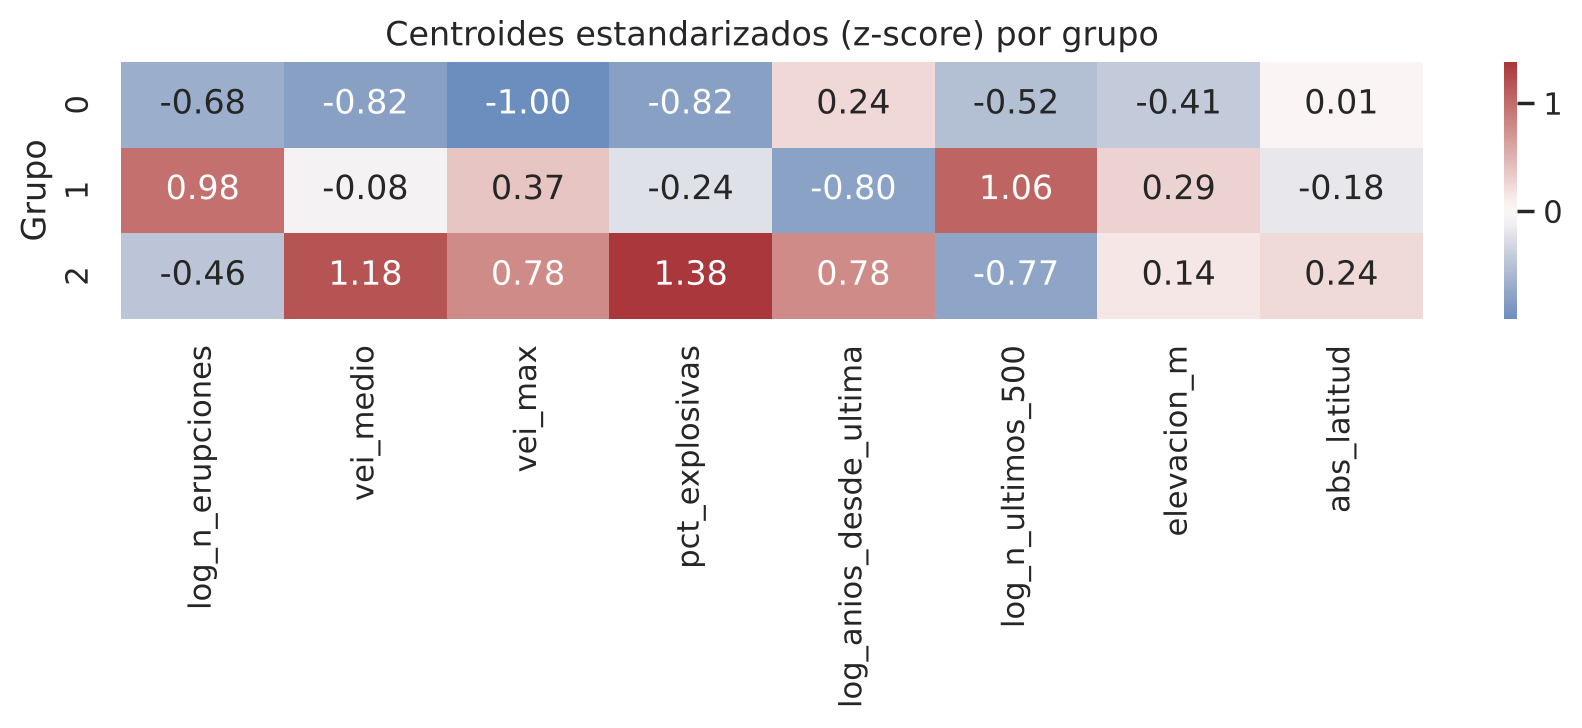

tipo_volcan  Stratovolcano  Caldera  Shield  Complex  Fissure vent
cluster                                                           
0                     45.2      5.0    12.9      5.4          12.9
1                     71.4     10.2     6.3      7.5           0.4
2                     59.1     13.4     5.9      2.7           2.7
cluster
0    United States, Indonesia, Japan
1    Indonesia, Japan, United States
2       United States, Russia, Japan
Name: pais, dtype: str
     cluster                  nombre           pais    tipo_volcan  n_erupciones  vei_medio  vei_max
469        0                Hualalai  United States         Shield            22       0.23      2.0
95         0                 Taveuni           Fiji         Shield            34       1.79      2.0
447        0                  Shasta  United States  Stratovolcano            22       1.00      4.0
57         1  Fournaise, Piton de la         France         Shield           198       1.04      5.0
591        1      

In [12]:
prof = vol.groupby("cluster").agg(
    n=("nombre","size"), erupciones_med=("n_erupciones","median"), vei_medio=("vei_medio","mean"), vei_max=("vei_max","mean"),
    pct_explosivas=("pct_explosivas","mean"), anios_desde_ultima=("anio_ultima", lambda s: (ANIO_REF - s).median()),
    erup_ult500=("n_ultimos_500","median"), elevacion_m=("elevacion_m","mean"), abs_lat=("abs_latitud","mean")).round(2)
prof.to_csv(f"{OUT_RES}/perfil_grupos.csv"); print(prof.to_string())
cen = pd.DataFrame(X, columns=FEATS).groupby(lab).mean()
plt.figure(figsize=(9, 3.8)); sns.heatmap(cen, annot=True, fmt=".2f", cmap="vlag", center=0); plt.title("Centroides estandarizados (z-score) por grupo"); plt.ylabel("Grupo")
savefig("09_heatmap_centroides")
tipo = pd.crosstab(vol.cluster, vol.tipo_volcan, normalize="index").mul(100).round(1)
top_t = vol.tipo_volcan.value_counts().head(5).index
tipo[top_t].to_csv(f"{OUT_RES}/tipo_por_grupo.csv"); print(tipo[top_t])
pais = vol.groupby("cluster")["pais"].agg(lambda s: ", ".join(s.value_counts().head(3).index)); pais.to_csv(f"{OUT_RES}/paises_por_grupo.csv"); print(pais)
ej = vol.sort_values("n_erupciones", ascending=False).groupby("cluster").head(3)[["cluster","nombre","pais","tipo_volcan","n_erupciones","vei_medio","vei_max"]].sort_values("cluster")
ej.round(2).to_csv(f"{OUT_RES}/ejemplos_por_grupo.csv", index=False); print(ej.round(2).to_string())

In [13]:
resumen = dict(n_volcanes=int(len(vol)), n_pca_90=n90, k_final=int(K), modelo_final=final_name,
               silhouette_base=float(ant_des.silhouette[0]), silhouette_final=float(ant_des.silhouette[1]),
               ch_base=float(ant_des.calinski_harabasz[0]), ch_final=float(ant_des.calinski_harabasz[1]),
               db_base=float(ant_des.davies_bouldin[0]), db_final=float(ant_des.davies_bouldin[1]),
               var_pc1=float(ev[0]), var_pc2=float(ev[1]), var_pc3=float(ev[2]))
json.dump(resumen, open(f"{OUT_RES}/resumen_u4.json", "w"), indent=2, ensure_ascii=False); print(resumen)

{'n_volcanes': 682, 'n_pca_90': 4, 'k_final': 3, 'modelo_final': 'K-Means estandarizado (k=3)', 'silhouette_base': 0.05156460146544151, 'silhouette_final': 0.29083209392105325, 'ch_base': 46.76435785280484, 'ch_final': 303.10620241235017, 'db_base': 3.5020367319674377, 'db_final': 1.217219496074421, 'var_pc1': 0.35564503535110203, 'var_pc2': 0.3212061404356905, 'var_pc3': 0.12663114178654444}
